# 머신러닝2 텀프로젝트: SCADA 데이터를 활용한 발전기 베어링 고장 징후 감지

## 프로젝트 개요

해상풍력 발전기는 고장이 나면 배를 타고 가서 수리해야 하기 때문에, 고장이 나기 전에 징후를 미리 파악하는 것이 중요하다.
본 프로젝트에서는 Kaggle의 Wind Turbine SCADA Data For Early Fault Detection 데이터 중 **Wind Farm A의 40번 터빈** 데이터를 사용한다.
이 터빈은 실제로 **발전기 베어링 고장(Generator bearing failure)** 기록이 있는 터빈이다.

센서값만 보고 현재 시점이 고장 징후 구간인지 아닌지를 분류하는 모델을 만드는 것이 목표이다.

## 사용 파일
- comma_40.csv : 40번 터빈의 SCADA 센서 데이터
- comma_feature_description.csv : 센서 이름(sensor_0 등)의 실제 의미
- comma_event_info.csv : 고장 기록 (고장 종류, 시작/끝 시점)

## 개발 환경
- 플랫폼: Google Colab
- 주요 라이브러리: pandas, numpy, matplotlib, scikit-learn


In [2]:
# =============================================================================
# 데이터 다운로드 (구글 드라이브 공유 폴더에서 csv 3개를 한 번에 받아 옴)
# =============================================================================
# gdown: 구글 드라이브 파일을 내려받는 도구 (Colab에 기본 설치되어 있음)
# --folder: 폴더 안의 파일을 전부 받음
# -O .: 현재 위치(노트북과 같은 위치)에 저장
!gdown --folder "https://drive.google.com/drive/folders/1IPledPf3t__XaB9IRg3UhIf3kE1HIxsX?usp=sharing" -O .

# 받아진 파일 확인
!ls *.csv

Retrieving folder contents
Processing file 1PuRlwAJ4ffa1PrcMPaUVGyFPb9-eZ_b_ comma_40.csv
Processing file 1OmuPccJCKIabHdURyZtP7BYY_juZV2-5 comma_event_info.csv
Processing file 15N7vi1l8sOdBH6wgmHzvT1ire_6OuiCH comma_feature_description.csv
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1PuRlwAJ4ffa1PrcMPaUVGyFPb9-eZ_b_
To: /content/comma_40.csv
100% 36.5M/36.5M [00:00<00:00, 48.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=1OmuPccJCKIabHdURyZtP7BYY_juZV2-5
To: /content/comma_event_info.csv
100% 1.67k/1.67k [00:00<00:00, 6.94MB/s]
Downloading...
From: https://drive.google.com/uc?id=15N7vi1l8sOdBH6wgmHzvT1ire_6OuiCH
To: /content/comma_feature_description.csv
100% 4.06k/4.06k [00:00<00:00, 17.6MB/s]
Download completed
comma_40.csv  comma_event_info.csv  comma_feature_description.csv


## 0단계: 라이브러리 설치 (필요한 경우만)

In [3]:
# Colab에서는 필요 없음. 개인 컴퓨터 Jupyter에서 라이브러리가 없다는 오류가 나면 아래 줄의 # 을 지우고 실행
# !pip install pandas numpy matplotlib scikit-learn

## 1단계: 데이터 로드 및 기본 정보 확인

### 목표
센서 데이터, 센서 설명 파일, 고장 기록 파일을 불러오고 데이터의 구조를 파악한다.

> Colab에서 실행할 때는 왼쪽 폴더 아이콘을 눌러 csv 파일 3개를 먼저 업로드한다.

In [4]:
# =============================================================================
# 라이브러리 불러오기
# =============================================================================
# numpy: 배열 계산용 라이브러리
import numpy as np

# pandas: csv 파일을 표(DataFrame) 형태로 불러오고 다루는 라이브러리
import pandas as pd

# matplotlib.pyplot: 그래프를 그리는 라이브러리
import matplotlib.pyplot as plt

# GroupShuffleSplit: 그룹(여기서는 날짜) 단위로 훈련/테스트를 나누는 함수
from sklearn.model_selection import GroupShuffleSplit

# StandardScaler: 각 특성을 평균 0, 표준편차 1로 맞추는 전처리 도구
from sklearn.preprocessing import StandardScaler

# 분류 모델 3종
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# 평가 지표
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix


print("="*60)
print("해상풍력 SCADA 데이터 - 발전기 베어링 고장 징후 감지")
print("="*60)


# =============================================================================
# 데이터 로드
# =============================================================================
# comma_ 파일은 쉼표(,)로 구분되어 있으므로 read_csv로 바로 읽을 수 있음
df = pd.read_csv("comma_40.csv")                          # 센서 데이터
desc = pd.read_csv("comma_feature_description.csv")      # 센서 설명
events = pd.read_csv("comma_event_info.csv")              # 고장 기록


# =============================================================================
# 기본 정보 출력
# =============================================================================
# shape의 첫 번째 값은 행(시점) 수, 두 번째 값은 열(컬럼) 수
print(f"\n총 행 수: {df.shape[0]}개")
print(f"컬럼 수: {df.shape[1]}개")
print(f"기록 기간: {df['time_stamp'].iloc[0]} ~ {df['time_stamp'].iloc[-1]}")
print(f"센서 설명 파일에 있는 센서 수: {len(desc)}개")

해상풍력 SCADA 데이터 - 발전기 베어링 고장 징후 감지

총 행 수: 56158개
컬럼 수: 86개
기록 기간: 2021-12-30 00:00:00 ~ 2023-01-26 13:00:00
센서 설명 파일에 있는 센서 수: 54개


### 분석 1-1
데이터는 10분 간격으로 기록되어 있고, 약 13개월 동안 56,158개 시점이 있다.
센서 54개 중 일부는 평균뿐 아니라 최소·최대·표준편차도 있어서 컬럼이 86개가 된다.

## 2단계: 컬럼 매핑

### 목표
sensor_13_avg처럼 암호화된 컬럼 이름을 센서 설명 파일을 참고해서 실제 의미가 있는 이름으로 바꾼다.

In [5]:
# =============================================================================
# 사용할 센서의 설명 확인
# =============================================================================
# isin(): 리스트 안에 있는 값만 골라내는 함수
use_sensors = ["sensor_0", "wind_speed_3", "sensor_13", "sensor_14",
               "sensor_18", "sensor_43", "power_30"]
print(desc[desc["sensor_name"].isin(use_sensors)][["sensor_name", "description"]])


# =============================================================================
# 컬럼 이름 바꾸기
# =============================================================================
# _avg는 10분 동안의 평균값이라는 뜻
# 딕셔너리 형태로 {원래 이름: 새 이름}을 만들어서 rename()에 넣음
rename_map = {
    "sensor_0_avg":     "Amb_Temp",        # 외부 온도 (°C)
    "wind_speed_3_avg": "Wind_Speed",      # 풍속 (m/s)
    "sensor_13_avg":    "Gen_Bear2_Temp",  # 발전기 베어링 2 온도, 구동 쪽 (°C)
    "sensor_14_avg":    "Gen_Bear1_Temp",  # 발전기 베어링 1 온도, 반대쪽 (°C)
    "sensor_18_avg":    "Gen_RPM",         # 발전기 회전수 (rpm)
    "sensor_43_avg":    "Nac_Temp",        # 나셀 내부 온도 (°C)
    "power_30_avg":     "Active_Power",    # 실제 발전량 (정격출력 기준 0~1로 정규화된 값)
}

# 기본 정보 컬럼(시각, id, 상태)과 위에서 고른 센서 컬럼만 남김
base_cols = ["time_stamp", "id", "status_type_id"]
data = df[base_cols + list(rename_map.keys())].rename(columns=rename_map)

# 시각 컬럼을 문자열에서 날짜 형식으로 변환 (나중에 날짜별로 묶을 때 사용)
data["time_stamp"] = pd.to_datetime(data["time_stamp"])

print("\n컬럼 매핑 완료")
print(data.head())

     sensor_name                                        description
0       sensor_0                                Ambient temperature
3   wind_speed_3                                          Windspeed
13     sensor_13     Temperature in generator bearing 2 (Drive End)
14     sensor_14  Temperature in generator bearing 1 (Non-Drive ...
18     sensor_18                     Generator rpm in latest period
30      power_30                                         Grid power
43     sensor_43                                Nacelle temperature

컬럼 매핑 완료
           time_stamp  id  status_type_id  Amb_Temp  Wind_Speed  \
0 2021-12-30 00:00:00   0               0      18.0         5.2   
1 2021-12-30 00:10:00   1               0      18.0         5.7   
2 2021-12-30 00:20:00   2               0      18.0         6.2   
3 2021-12-30 00:30:00   3               0      18.0         6.3   
4 2021-12-30 00:40:00   4               0      18.0         6.6   

   Gen_Bear2_Temp  Gen_Bear1_Temp  Gen_RPM 

## 3단계: 정답(라벨) 정의

### 목표
이 데이터에는 정답 컬럼이 없기 때문에 직접 만든다.

### 라벨 기준
comma_event_info.csv에 있는 40번 터빈의 실제 고장 기록을 사용한다.
고장 구간(event_start_id ~ event_end_id)에 있는 시점은 1(고장 징후), 나머지는 0(정상)으로 한다.

status_type_id를 쓰지 않은 이유는, 정상(0)이 아닌 값이 대부분 5(기타)여서 이것을 고장이라고 보기 어려웠기 때문이다.
실제로 고장 구간 안의 시점들도 대부분 status_type_id가 0으로 기록되어 있었다.

In [6]:
# =============================================================================
# 40번 터빈의 고장 기록 꺼내기
# =============================================================================
# event_id가 40인 행을 고르고, iloc[0]으로 그 한 줄을 꺼냄
ev = events[events["event_id"] == 40].iloc[0]

print(f"고장 종류: {ev['event_description']}")
print(f"고장 구간: {ev['event_start']} ~ {ev['event_end']}")
print(f"id 범위: {ev['event_start_id']} ~ {ev['event_end_id']}")


# =============================================================================
# 라벨 만들기
# =============================================================================
# between(a, b): 값이 a 이상 b 이하이면 True
# astype(int): True/False를 1/0으로 바꿈
data["label"] = data["id"].between(ev["event_start_id"], ev["event_end_id"]).astype(int)

# 불리언 비교 후 합계를 구하는 방식으로 개수 세기
normal_count = np.sum(data["label"] == 0)
fault_count = np.sum(data["label"] == 1)
print(f"\n정상(0): {normal_count}개")
print(f"고장 징후(1): {fault_count}개")


# =============================================================================
# 참고: 고장 구간 안의 status_type_id 분포
# =============================================================================
print("\n고장 구간 안의 status_type_id 개수")
print(data[data["label"] == 1]["status_type_id"].value_counts())

고장 종류: Generator bearing failure
고장 구간: 2022-12-24 00:00:00 ~ 2023-01-24 13:00:00
id 범위: 51363 ~ 55870

정상(0): 51650개
고장 징후(1): 4508개

고장 구간 안의 status_type_id 개수
status_type_id
0    4002
5     505
3       1
Name: count, dtype: int64


## 4단계: 데이터 전처리

### 목표
결측치, 센서 오류값, 터빈이 멈춰 있는 시점을 제거한다.

### 처리 내용
1. 결측치 제거: 결측치가 2행밖에 없어서 삭제했다.
2. 센서 오류값 제거: 베어링 온도에 205°C가 수백 번 반복해서 나온다. 평소 온도가 40~60°C이고, 그 시점의 발전량이 0이어서 터빈이 멈춰 있는 상태였다. 멈춘 터빈의 베어링이 205°C일 수는 없으므로 센서 오류값으로 판단했다. 그대로 두면 모델이 205°C면 고장이라고 외워 버릴 수 있다.
3. 가동 중인 시점만 사용: 발전량이 0 이하(마이너스 포함)인 시점은 터빈이 멈춰 있어서 베어링이 식어 있다. 부하에 따른 발열을 보려면 돌아가고 있는 시점만 봐야 하므로, status_type_id가 0이고 발전량이 0.01보다 큰 시점만 남겼다.

In [7]:
print(f"처음 행 수: {len(data)}")

# =============================================================================
# 1) 결측치 제거
# =============================================================================
# isnull().sum(): 컬럼별 결측치 개수
print(f"\n결측치 개수:\n{data.isnull().sum()[data.isnull().sum() > 0]}")
data = data.dropna()
print(f"결측치 제거 후: {len(data)}")


# =============================================================================
# 2) 센서 오류값(205°C) 제거
# =============================================================================
# 두 베어링 중 하나라도 150°C 이상이면 오류값으로 봄
# | : 넘파이/판다스에서 OR 조건 (괄호 필수)
err_mask = (data["Gen_Bear1_Temp"] >= 150) | (data["Gen_Bear2_Temp"] >= 150)
print(f"\n150°C 이상 행 수: {np.sum(err_mask)}")
print(f"그때의 평균 발전량: {data.loc[err_mask, 'Active_Power'].mean():.3f}")

# ~ : 불리언 마스크 뒤집기 (오류값이 아닌 행만 남김)
data = data[~err_mask]
print(f"센서 오류값 제거 후: {len(data)}")


# =============================================================================
# 3) 가동 중인 시점만 남기기
# =============================================================================
print(f"\n발전량이 0 이하인 행 수: {np.sum(data['Active_Power'] <= 0)}")

# & : AND 조건 (둘 다 만족해야 True)
run_mask = (data["status_type_id"] == 0) & (data["Active_Power"] > 0.01)
data = data[run_mask].copy()
print(f"가동 중 시점만 남긴 후: {len(data)}")

print(f"\n정상(0): {np.sum(data['label'] == 0)}개")
print(f"고장 징후(1): {np.sum(data['label'] == 1)}개")
print(f"고장 징후 비율: {data['label'].mean()*100:.2f}%")

처음 행 수: 56158

결측치 개수:
Gen_Bear1_Temp    2
dtype: int64
결측치 제거 후: 56156

150°C 이상 행 수: 834
그때의 평균 발전량: -0.001
센서 오류값 제거 후: 55322

발전량이 0 이하인 행 수: 18377
가동 중 시점만 남긴 후: 34345

정상(0): 32247개
고장 징후(1): 2098개
고장 징후 비율: 6.11%


### 분석 4-1
전처리 후 고장 징후 구간이 전체의 약 6%밖에 되지 않는다. 클래스가 매우 불균형하기 때문에,
모든 시점을 정상이라고 예측해도 정확도가 90% 이상 나온다. 따라서 정확도만으로 모델을 평가하면 안 되고,
실제 고장 중 얼마나 잡아냈는지(재현율)를 같이 봐야 한다.

## 5단계: 특성 공학 및 변수 선택

### 목표
새로운 특성을 하나 만들고, 정상 구간과 고장 구간을 비교해서 학습에 사용할 변수를 고른다.

### 새로 만든 특성: 두 베어링의 온도 차이
발전기에는 베어링이 두 개(구동 쪽, 반대쪽) 있다. 한쪽 베어링에 문제가 생기면 그쪽만 마찰열이 늘어나서 두 베어링의 온도 차이가 벌어질 것이라고 생각했다.

In [8]:
# =============================================================================
# 새 특성 만들기
# =============================================================================
# 베어링1(반대쪽) 온도 - 베어링2(구동 쪽) 온도
data["Bear_Temp_Diff"] = data["Gen_Bear1_Temp"] - data["Gen_Bear2_Temp"]


# =============================================================================
# 정상 구간 vs 고장 구간 평균 비교
# =============================================================================
compare_cols = ["Gen_Bear1_Temp", "Gen_Bear2_Temp", "Bear_Temp_Diff", "Nac_Temp",
                "Amb_Temp", "Active_Power", "Gen_RPM", "Wind_Speed"]

print("[정상 구간 vs 고장 징후 구간 평균]")
for col in compare_cols:
    normal_mean = data[data["label"] == 0][col].mean()
    fault_mean = data[data["label"] == 1][col].mean()
    print(f"   {col:15s}: 정상 {normal_mean:8.2f} / 고장 징후 {fault_mean:8.2f}")

[정상 구간 vs 고장 징후 구간 평균]
   Gen_Bear1_Temp : 정상    62.09 / 고장 징후    56.13
   Gen_Bear2_Temp : 정상    51.97 / 고장 징후    41.36
   Bear_Temp_Diff : 정상    10.12 / 고장 징후    14.77
   Nac_Temp       : 정상    32.30 / 고장 징후    27.42
   Amb_Temp       : 정상    20.16 / 고장 징후    15.06
   Active_Power   : 정상     0.36 / 고장 징후     0.39
   Gen_RPM        : 정상  1457.16 / 고장 징후  1488.17
   Wind_Speed     : 정상     7.51 / 고장 징후     7.53


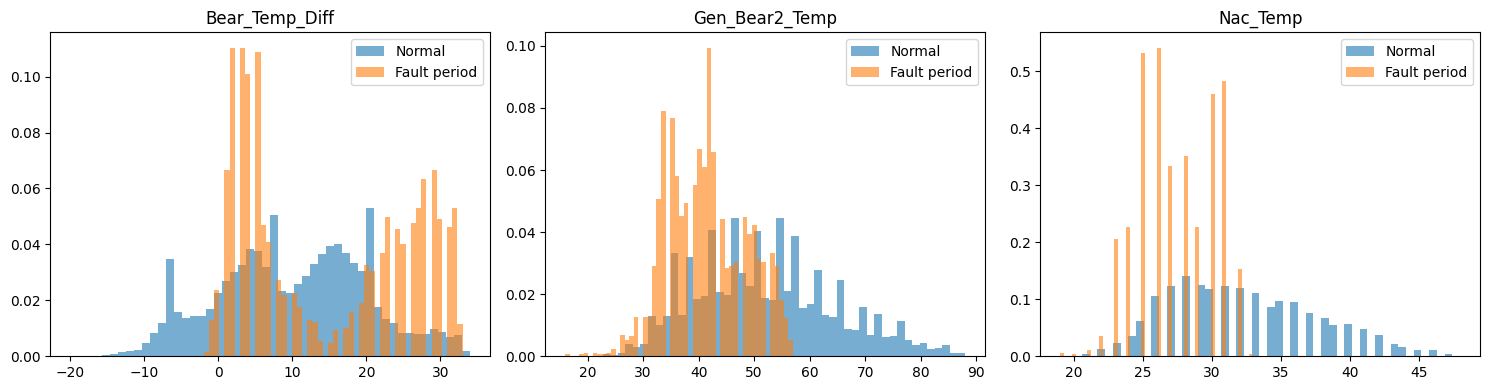

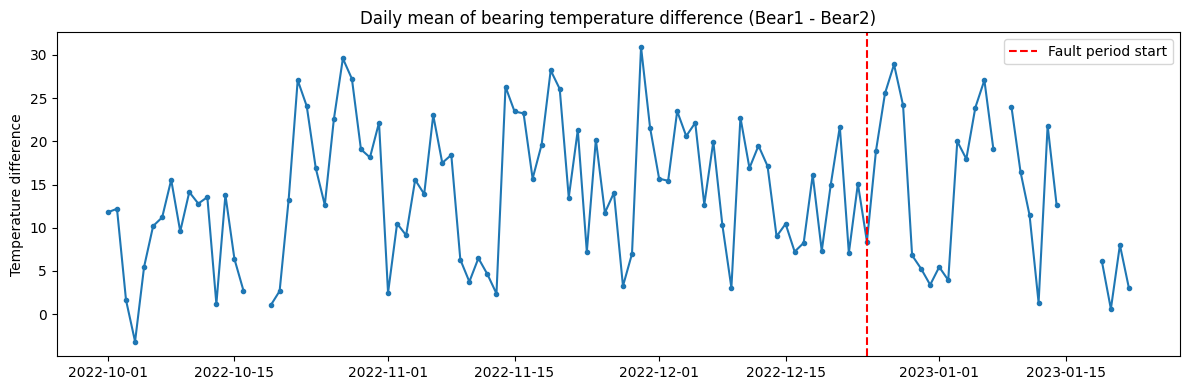

In [9]:
# =============================================================================
# 분포 비교 그래프
# =============================================================================
# density=True: 개수가 아니라 비율로 그려서 개수가 다른 두 그룹을 비교할 수 있게 함
# 그래프 글자는 Colab에서 한글이 깨지는 것을 막기 위해 영어로 씀
plt.figure(figsize=(15, 4))
for i, col in enumerate(["Bear_Temp_Diff", "Gen_Bear2_Temp", "Nac_Temp"]):
    plt.subplot(1, 3, i + 1)
    plt.hist(data[data["label"] == 0][col], bins=50, alpha=0.6, density=True, label="Normal")
    plt.hist(data[data["label"] == 1][col], bins=50, alpha=0.6, density=True, label="Fault period")
    plt.title(col)
    plt.legend()
plt.tight_layout()
plt.savefig("fig1_normal_vs_fault.png", dpi=150)
plt.show()


# =============================================================================
# 고장 전후 두 베어링 온도 차이 변화 (하루 평균)
# =============================================================================
# resample("D"): 하루 단위로 묶기
daily = data.set_index("time_stamp")["Bear_Temp_Diff"].resample("D").mean()
recent = daily["2022-10-01":]   # 고장 약 3개월 전부터

plt.figure(figsize=(12, 4))
plt.plot(recent.index, recent.values, marker=".")
plt.axvline(pd.to_datetime(ev["event_start"]), color="red", linestyle="--", label="Fault period start")
plt.title("Daily mean of bearing temperature difference (Bear1 - Bear2)")
plt.ylabel("Temperature difference")
plt.legend()
plt.tight_layout()
plt.savefig("fig2_bear_diff_timeline.png", dpi=150)
plt.show()

### 분석 5-1
고장 징후 구간에서 두 베어링의 온도 차이 평균이 약 10.1°C에서 14.8°C로 커졌다.
한쪽 베어링에만 마찰열이 늘었다는 뜻으로 볼 수 있어서 고장 부품(발전기 베어링)과 연결된다.

반면 베어링 온도 자체나 나셀 온도는 고장 구간에서 오히려 낮았는데, 고장 구간이 겨울(12월~1월)이라 주변 온도가 낮았기 때문으로 보인다.

### 최종 선택 변수 (7개)
- Gen_Bear1_Temp, Gen_Bear2_Temp : 고장 부품인 발전기 베어링의 상태를 직접 보여 줌
- Bear_Temp_Diff : 한쪽 베어링만 이상해지면 차이가 벌어짐
- Nac_Temp : 베어링이 뜨거운 게 주변이 더워서인지 구분하기 위함
- Active_Power, Gen_RPM, Wind_Speed : 베어링이 뜨거운 게 일을 많이 해서(부하가 커서)인지 구분하기 위함

외부 온도(Amb_Temp)는 뺐다. 고장 구간이 겨울이라 넣으면 모델이 추우면 고장이라는 계절 규칙을 배울 수 있기 때문이다.

In [10]:
# =============================================================================
# 학습에 사용할 특성 선택
# =============================================================================
features = ["Gen_Bear1_Temp", "Gen_Bear2_Temp", "Bear_Temp_Diff",
            "Nac_Temp", "Active_Power", "Gen_RPM", "Wind_Speed"]

X = data[features].values   # .values: DataFrame을 넘파이 배열로 변환
y = data["label"].values

print(f"X 크기: {X.shape}")
print(f"y 크기: {y.shape}")


# =============================================================================
# 전처리된 데이터 저장 (제출용)
# =============================================================================
data[["time_stamp", "id"] + features + ["label"]].to_csv("preprocessed_turbine40.csv", index=False)
print("\n전처리된 데이터 저장 완료: preprocessed_turbine40.csv")

X 크기: (34345, 7)
y 크기: (34345,)

전처리된 데이터 저장 완료: preprocessed_turbine40.csv


## 6단계: 훈련/테스트 데이터 분할 및 표준화

### 목표
데이터를 훈련용 70%, 테스트용 30%로 나누고 표준화한다.

### 날짜 단위로 나눈 이유
데이터가 10분 간격이라 바로 옆 시점끼리는 값이 거의 같다. train_test_split으로 무작위로 나누면
같은 날 10시 데이터로 학습하고 10시 10분 데이터로 테스트하는 셈이 되어 성능이 실제보다 높게 나온다.
그래서 GroupShuffleSplit으로 같은 날의 데이터는 모두 훈련용이거나 모두 테스트용이 되도록 나눴다.

원본 데이터의 train_test 컬럼은 고장 구간이 전부 prediction 쪽에 있어서 사용하지 않았다.

In [11]:
# =============================================================================
# 날짜 단위 분할
# =============================================================================
# groups: 같은 그룹(같은 날짜)은 한쪽에만 들어감
# test_size=0.3: 그룹(날짜)의 30%를 테스트로 사용
# random_state=42: 실행할 때마다 같은 결과가 나오도록 고정
days = data["time_stamp"].dt.date.values
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

# split()은 훈련/테스트에 들어갈 행 번호를 돌려줌
train_idx, test_idx = next(gss.split(X, y, groups=days))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print(f"훈련 세트: {X_train.shape}, 고장 징후 비율 {y_train.mean()*100:.2f}%")
print(f"테스트 세트: {X_test.shape}, 고장 징후 비율 {y_test.mean()*100:.2f}%")


# =============================================================================
# 데이터 표준화
# =============================================================================
# 온도(수십), 회전수(수천)처럼 특성마다 크기가 다르므로 평균 0, 표준편차 1로 맞춤
# 훈련 데이터로 평균/표준편차 계산 후 변환, 테스트 데이터는 변환만 (데이터 누수 방지)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # 계산 + 변환
X_test_scaled = scaler.transform(X_test)         # 변환만

print("\n표준화 완료")

훈련 세트: (23554, 7), 고장 징후 비율 4.31%
테스트 세트: (10791, 7), 고장 징후 비율 10.05%

표준화 완료


## 7단계: 모델 학습 및 평가

### 목표
로지스틱 회귀, 결정 트리, RBF 커널 SVM 세 모델을 학습하고 성능을 비교한다.

### 모델 선택 이유
- 로지스틱 회귀 : 가장 단순한 기준 모델. 다른 모델과 비교하는 기준으로 사용
- 결정 트리 : 어떤 특성이 몇 이상이면 고장이라는 식으로 규칙을 사람이 읽을 수 있음
- RBF 커널 SVM : 정상과 고장의 경계가 직선이 아닐 수 있어서 곡선 경계를 만들 수 있는 모델을 사용

### 불균형 처리
세 모델 모두 class_weight='balanced'를 사용했다. 개수가 적은 고장 징후 쪽을 틀리면 벌점을 더 크게 줘서 모델이 고장을 무시하지 않게 한다.

In [12]:
# =============================================================================
# 로지스틱 회귀
# =============================================================================
# C: 규제 강도 (기본값 1.0)
# class_weight='balanced': 적은 클래스(고장 징후)에 가중치를 더 줌
# max_iter: 학습 반복 횟수 (기본값 100으로는 수렴이 안 될 수 있어서 늘림)
lr_model = LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)


# =============================================================================
# 결정 트리
# =============================================================================
# criterion: 불순도 지표 (지니 불순도 사용)
# max_depth: 트리의 최대 깊이 (너무 깊으면 과적합되므로 5로 제한)
# 결정 트리는 특성의 크기 차이에 영향을 받지 않으므로 표준화 전 데이터를 사용
tree_model = DecisionTreeClassifier(criterion='gini', max_depth=5,
                                    class_weight='balanced', random_state=42)
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)


# =============================================================================
# RBF 커널 SVM
# =============================================================================
# kernel='rbf': 비선형 결정 경계 생성
# gamma='scale': 커널 계수 자동 설정
# 데이터가 많아서 학습에 1분 정도 걸릴 수 있음
rbf_svm = SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced', random_state=42)
rbf_svm.fit(X_train_scaled, y_train)
y_pred_svm = rbf_svm.predict(X_test_scaled)

print("세 모델 학습 완료")

세 모델 학습 완료


In [13]:
# =============================================================================
# 성능 비교
# =============================================================================
# 정확도: 전체 중 맞춘 비율
# 정밀도: 고장이라고 예측한 것 중 실제 고장 비율
# 재현율: 실제 고장 중 고장이라고 예측한 비율
# F1: 정밀도와 재현율의 조화 평균
print("[세 분류 모델 비교]")
for name, pred in [('로지스틱 회귀', y_pred_lr), ('결정 트리', y_pred_tree),
                   ('RBF 커널 SVM', y_pred_svm)]:
    print(f"\n   {name}")
    print(f"      정확도: {accuracy_score(y_test, pred)*100:.2f}%")
    print(f"      정밀도: {precision_score(y_test, pred)*100:.2f}%")
    print(f"      재현율: {recall_score(y_test, pred)*100:.2f}%")
    print(f"      F1    : {f1_score(y_test, pred)*100:.2f}%")


# =============================================================================
# 비교용: 모두 정상(0)이라고 예측하는 경우
# =============================================================================
# np.zeros: 0으로 채운 배열 생성
y_pred_zero = np.zeros(len(y_test), dtype=int)
print(f"\n[참고] 모두 정상이라고 예측했을 때")
print(f"      정확도: {accuracy_score(y_test, y_pred_zero)*100:.2f}%")
print(f"      재현율: {recall_score(y_test, y_pred_zero)*100:.2f}%")

[세 분류 모델 비교]

   로지스틱 회귀
      정확도: 75.98%
      정밀도: 27.80%
      재현율: 87.08%
      F1    : 42.14%

   결정 트리
      정확도: 72.50%
      정밀도: 25.89%
      재현율: 93.27%
      F1    : 40.53%

   RBF 커널 SVM
      정확도: 80.73%
      정밀도: 33.43%
      재현율: 92.62%
      F1    : 49.13%

[참고] 모두 정상이라고 예측했을 때
      정확도: 89.95%
      재현율: 0.00%


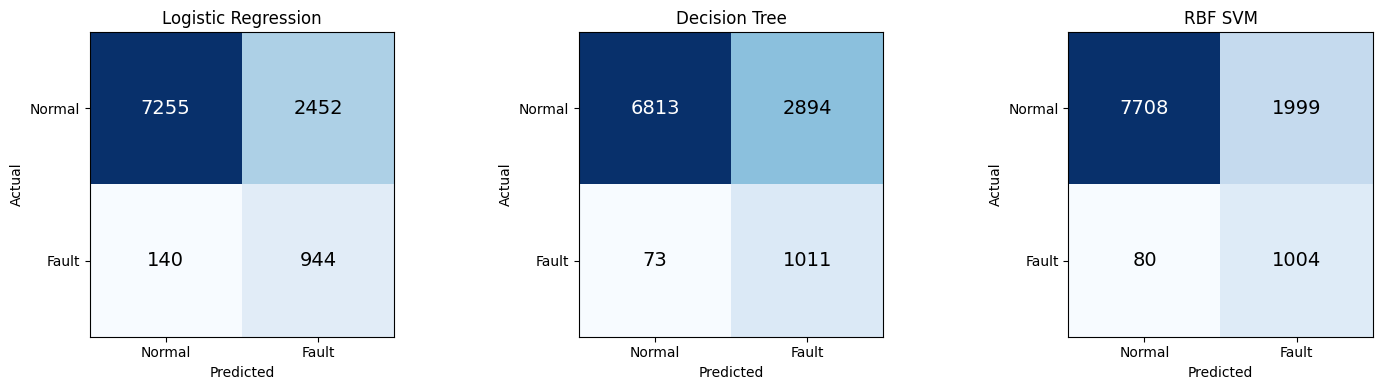

In [14]:
# =============================================================================
# 혼동 행렬
# =============================================================================
# confusion_matrix(실제, 예측)
# [[정상을 정상으로, 정상을 고장으로],
#  [고장을 정상으로, 고장을 고장으로]]
plt.figure(figsize=(15, 4))
for i, (name, pred) in enumerate([('Logistic Regression', y_pred_lr),
                                  ('Decision Tree', y_pred_tree),
                                  ('RBF SVM', y_pred_svm)]):
    cm = confusion_matrix(y_test, pred)
    plt.subplot(1, 3, i + 1)
    plt.imshow(cm, cmap='Blues')
    for r in range(2):
        for c in range(2):
            # 진한 칸은 흰 글씨, 연한 칸은 검은 글씨
            color = 'white' if cm[r, c] > cm.max() / 2 else 'black'
            plt.text(c, r, cm[r, c], ha='center', va='center', fontsize=14, color=color)
    plt.xticks([0, 1], ['Normal', 'Fault'])
    plt.yticks([0, 1], ['Normal', 'Fault'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(name)
plt.tight_layout()
plt.savefig("fig3_confusion_matrix.png", dpi=150)
plt.show()

### 분석 7-1
세 모델 모두 실제 고장 징후 구간의 약 87~93%를 잡아냈다. 모두 정상이라고 예측하면 정확도는 90%지만 재현율이 0%이므로, 정확도만 보면 좋은 모델처럼 보이는 함정이 있다는 것을 확인했다.

대신 정밀도가 약 26~33%로 낮아서, 고장이라고 경보를 울린 것 중 실제 고장은 3~4개 중 1개 정도이다.
해상풍력은 고장을 놓치면 배와 크레인을 빌려야 해서 비용이 매우 크고, 잘못된 경보는 점검 한 번이면 되기 때문에 재현율을 더 중요하게 봤다.

### 분석 7-2
F1 기준으로 RBF 커널 SVM이 가장 좋았다. 로지스틱 회귀(직선 경계)보다 좋았으므로 정상과 고장 징후의 경계가 직선이 아니라고 볼 수 있다.

## 8단계: 결과 해석

### 목표
결정 트리가 어떤 특성을 중요하게 봤는지 확인하고, 계절의 영향이 있는지 확인한다.

특성 중요도
   Nac_Temp: 0.593
   Gen_Bear2_Temp: 0.164
   Bear_Temp_Diff: 0.129
   Active_Power: 0.114
   Gen_Bear1_Temp: 0.001
   Gen_RPM: 0.000
   Wind_Speed: 0.000


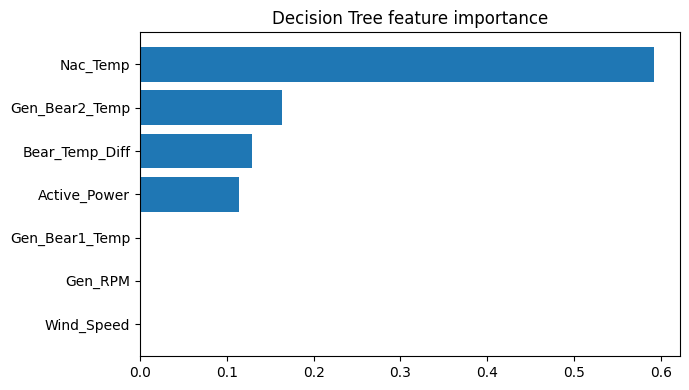

In [15]:
# =============================================================================
# 특성 중요도
# =============================================================================
# feature_importances_: 각 특성이 불순도를 줄이는 데 기여한 정도
importances = tree_model.feature_importances_
order = np.argsort(importances)[::-1]     # 중요도가 큰 순서

print("특성 중요도")
for idx in order:
    print(f"   {features[idx]}: {importances[idx]:.3f}")

plt.figure(figsize=(7, 4))
plt.barh([features[i] for i in order[::-1]], importances[order[::-1]])
plt.title("Decision Tree feature importance")
plt.tight_layout()
plt.savefig("fig4_feature_importance.png", dpi=150)
plt.show()

In [16]:
# =============================================================================
# 계절 영향 확인
# =============================================================================
# 고장과 상관없는 작년 겨울(2022년 1월) 정상 데이터를 고장이라고 잘못 예측한 비율과
# 전체 정상 데이터를 잘못 예측한 비율을 비교
test_time = data["time_stamp"].values[test_idx]
winter_mask = test_time < np.datetime64("2022-02-01")
normal_mask = (y_test == 0)

print("[정상 데이터를 고장으로 잘못 예측한 비율]")
for name, pred in [('로지스틱 회귀', y_pred_lr), ('결정 트리', y_pred_tree),
                   ('RBF 커널 SVM', y_pred_svm)]:
    print(f"   {name}: 전체 {pred[normal_mask].mean()*100:.2f}% / 작년 겨울 {pred[winter_mask].mean()*100:.2f}%")

[정상 데이터를 고장으로 잘못 예측한 비율]
   로지스틱 회귀: 전체 25.26% / 작년 겨울 36.99%
   결정 트리: 전체 29.81% / 작년 겨울 34.89%
   RBF 커널 SVM: 전체 20.59% / 작년 겨울 29.09%


### 분석 8-1
결정 트리는 나셀 온도를 가장 중요하게 봤고, 그다음이 베어링2 온도와 두 베어링의 온도 차이였다.
베어링 관련 특성이 상위에 있어서 고장 부품과 연결되지만, 나셀 온도가 가장 중요하게 나온 것은 고장 구간이 겨울이라 그런 것으로 보인다.

실제로 고장과 상관없는 작년 겨울 정상 데이터에서 잘못된 경보 비율이 전체 평균보다 높았다.
외부 온도를 빼서 계절 영향을 줄이려고 했지만 완전히 없애지는 못했다.

### 분석 8-2
두 베어링 온도 차이의 하루 평균 그래프를 보면, 고장 구간이 시작되기 전에 꾸준히 올라가는 추세는 보이지 않았다.
그래서 이번 모델은 고장 징후 구간인지는 꽤 잘 맞히지만, 고장 며칠 전부터 미리 알 수 있는지까지 보여 주지는 못한다.

## 결론
베어링 온도와 두 베어링의 온도 차이를 중심으로 한 7개 특성으로 발전기 베어링 고장 징후 구간의 약 90%를 감지할 수 있었다.
세 모델 중에서는 RBF 커널 SVM이 F1 기준으로 가장 좋았다.

다만 오경보가 많고 계절의 영향을 완전히 떼어 내지 못했다는 한계가 있다.
여러 해의 겨울 데이터를 함께 쓰거나, 고장이 없는 다른 터빈의 같은 시기 데이터와 비교하면 개선할 수 있을 것이다.